In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from src.functions_generator import FunctionsGenerator
from src.heat1D_crank_nicolson_solver import Heat1DCrankNicolson

plt.style.use("styles/plots.mplstyle")
np.random.seed(42)

In [ ]:
def phi_theta(omega,a,b,c):
    return a*omega + b*omega**3 + c*omega**5

def R_theta(omega,a,b,c):
    return a + b*omega**2 + c*omega**4

def W_theta(G, phi, R):
    return np.conjugate(G)*np.exp(1j * phi) / (np.abs(G)**2 + R)

In [ ]:
# Parametri simulazione
L = 1
Tf = 10
nt = 5000
D = 1
wanted_r = 0.5
h = 1
l = 1

In [ ]:
# Inizializza solver
solver = Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)

# Function generator
f_generator = FunctionsGenerator(solver.t_array, l=1)

In [ ]:
n = solver.nt*2-1

impulse_response = solver.impulse_response()[-1]
IMPULSE_RESPONSE = np.fft.rfft(impulse_response, n) # Trasformata della risposta all'impulso

#f = np.sin(solver.t_array*2*np.pi/solver.Tf)
f = f_generator.generate_from_white_noise()
F = np.fft.rfft(f, n) # Trasformata del bordo 0

g = solver.solve_from_impulse_response(f, impulse_response)
G = np.fft.rfft(g, n) # Trasformata del bordo L

In [ ]:
'''
a_phi, b_phi, c_phi = -0.2, 0, 0
a_R, b_R, c_R = 0, 1e-3, 0

omegas = np.fft.rfftfreq(n, d=solver.dt) * 2 * np.pi

W = W_theta(IMPULSE_RESPONSE, phi = phi_theta(omegas,a_phi, b_phi, c_phi), R=R_theta(omegas,a_R, b_R, c_R))
F_RECONSTRUCTED = (W * G) / solver.dt
f_reconstructed = np.fft.irfft(F_RECONSTRUCTED,n)[:solver.nt]

# Plot ricostruzioni
plt.figure()
plt.plot(solver.t_array, f, label="f")
plt.plot(solver.t_array, g, label="g")
plt.plot(solver.t_array, f_reconstructed, label="f_rec")
plt.legend()
plt.grid()
plt.show()

# Plot funzioni phi, R
plt.figure()
plt.plot(omegas, phi_theta(omegas, a_phi, b_phi, c_phi), label="phi")
plt.plot(omegas, R_theta(omegas, a_R, b_R, c_R), label="R")
plt.legend()
plt.grid()
plt.show()
'''


'\na_phi, b_phi, c_phi = -0.2, 0, 0\na_R, b_R, c_R = 0, 1e-3, 0\n\nomegas = np.fft.rfftfreq(n, d=solver.dt) * 2 * np.pi\n\nW = W_theta(IMPULSE_RESPONSE, phi = phi_theta(omegas,a_phi, b_phi, c_phi), R=R_theta(omegas,a_R, b_R, c_R))\nF_RECONSTRUCTED = (W * G) / solver.dt\nf_reconstructed = np.fft.irfft(F_RECONSTRUCTED,n)[:solver.nt]\n\n# Plot ricostruzioni\nplt.figure()\nplt.plot(solver.t_array, f, label="f")\nplt.plot(solver.t_array, g, label="g")\nplt.plot(solver.t_array, f_reconstructed, label="f_rec")\nplt.legend()\nplt.grid()\nplt.show()\n\n# Plot funzioni phi, R\nplt.figure()\nplt.plot(omegas, phi_theta(omegas, a_phi, b_phi, c_phi), label="phi")\nplt.plot(omegas, R_theta(omegas, a_R, b_R, c_R), label="R")\nplt.legend()\nplt.grid()\nplt.show()\n'

interactive(children=(FloatSlider(value=0.0, description='a_phi', max=5.0, min=-5.0, step=0.01), FloatSlider(v…

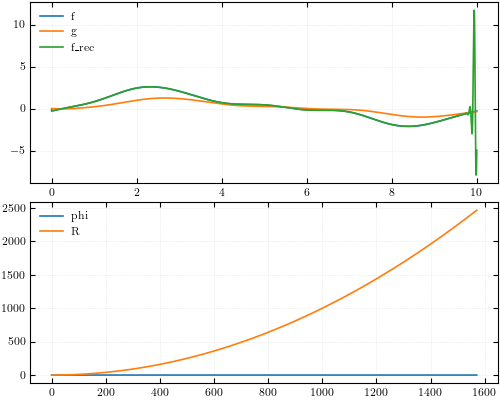

In [ ]:
%matplotlib widget

from ipywidgets import interact, FloatSlider

omegas = np.fft.rfftfreq(n, d=solver.dt) * 2 * np.pi

fig, axes = plt.subplots(2, 1, figsize=(5, 4))

ax1, ax2 = axes

line_f, = ax1.plot(solver.t_array, f, label="f")
line_g, = ax1.plot(solver.t_array, g, label="g")
line_frec, = ax1.plot(solver.t_array, f, label="f_rec")

ax1.legend()
ax1.grid()

line_phi, = ax2.plot(omegas, phi_theta(omegas, 0, 0, 0), label="phi")
line_R, = ax2.plot(omegas, R_theta(omegas, 0, 1e-3, 0), label="R")

ax2.legend()
ax2.grid()


def update(
    a_phi=0,
    b_phi=0.0,
    c_phi=0.0,
    a_R=0.0,
    b_R=1e-3,
    c_R=0.0
):
    # Compute functions theta and R
    phi_vals = phi_theta(omegas, a_phi, b_phi, c_phi)
    R_vals = R_theta(omegas, a_R, b_R, c_R)

    W = W_theta(
        IMPULSE_RESPONSE,
        phi=phi_vals,
        R=R_vals
    )

    F_RECONSTRUCTED = (W * G) / solver.dt
    f_reconstructed = np.fft.irfft(F_RECONSTRUCTED, n)[:solver.nt]

    # Update signal
    line_frec.set_ydata(f_reconstructed)

    # Update plot phi/R
    line_phi.set_ydata(phi_vals)
    line_R.set_ydata(R_vals)

    # Autoscale
    ax1.relim()
    ax1.autoscale_view()

    ax2.relim()
    ax2.autoscale_view()

    fig.canvas.draw_idle()


interact(
    update,

    a_phi=FloatSlider(value=0, min=-5, max=5, step=0.01),
    b_phi=FloatSlider(value=0.0, min=-1, max=1, step=1e-3),
    c_phi=FloatSlider(value=0.0, min=-1, max=1, step=1e-3),

    a_R=FloatSlider(value=0.0, min=-1, max=1, step=1e-3),
    b_R=FloatSlider(value=1e-3, min=0, max=1e-1, step=1e-4),
    c_R=FloatSlider(value=0.0, min=-1, max=1, step=1e-3),
)

plt.show()
